In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from cmcrameri import cm

In [16]:
def open_kymographs(condition:str, channel:str, ratio_calculation:str = 'RoM', root_path:str = '../LineProfiles/'):
    #Opens the perinuclear(N) and peripheral(P) kymographs generated by the kymo_plotting_notebook jupyter notebook.
    #The root_path is the path to the LineProfiles folder in which each condition has its own folder.
    #Channel can be either red, green, or ratio.
    #Condition can be either TRAK1_kd, TRAK2_kd, MYO19_kd, galactose, galactose_48h, acute_galactose, starvation_control, wt or wt_redraw
    #If you're interested in the ratios you can either choose to look at the ratio of means (RoM) or the mean of ratios (MoR)
    #The output is two dataframes, the first for the perinuclear kymograph and the second for the peripheral kymograph.

    folder = '/kymographs/'
    
    if channel == 'ratio':
        if ratio_calculation == 'MoR':
            filename_N = root_path + condition + folder + 'mean_of_ratios_N.csv'
            filename_P = root_path + condition + folder + 'mean_of_ratios_P.csv'
        elif ratio_calculation == 'RoM':
            filename_N = root_path + condition + folder + 'ratio_of_means_N.csv'
            filename_P = root_path + condition + folder + 'ratio_of_means_P.csv'
        elif ratio_calculation == 'median':
            filename_N = root_path + condition + folder + 'median_of_ratios_N.csv'
            filename_P = root_path + condition + folder + 'median_of_ratios_P.csv'
        else:
            print('Invalid ratio calculation')
            return
    elif channel == 'red' or channel =='green':
        filename_N = root_path + condition + folder + channel + '_N.csv'
        filename_P = root_path + condition + folder + channel + '_P.csv'
    else:
        print('Invalid channel')
        return

    df_N = pd.read_csv(filename_N).rename(columns={'Unnamed: 0':'time (min)'})
    df_P = pd.read_csv(filename_P).rename(columns={'Unnamed: 0':'time (min)'})
    df_N.set_index('time (min)', inplace=True)
    df_P.set_index('time (min)', inplace=True)
    
    return df_N, df_P

def bin_dataframe(df, width:int):
    #Bins every row of a dataframe by a given width
    #source: https://stackoverflow.com/questions/21921178/binning-a-numpy-array
    array = df.values
    bin_array = np.zeros((array.shape[0], array.shape[1] // width))
    for i in range(len(array)):
        bin_array[i] = array[i][:(array[i].size // width) * width].reshape(-1, width).mean(axis=1)

    header_array = df.columns.values.astype(float)
    header_bin = header_array[:(header_array.size // width) * width].reshape(-1, width).mean(axis=1)

    return pd.DataFrame(bin_array, columns=header_bin, index=df.index) 

def rewrite_tidy_dataframe(df, channel:str, left_bound:float = None, right_bound:float = None):
    #Takes as input a dataframe generated with the lineprofile_to_tidy notebook
    #Returns a dataframe with the specified channel and cropped to the specified bounds
    if channel == 'ratio':
        channel = 'ratio (red/green)'
    elif channel == 'red' or channel == 'green':
        channel = 'average ' + channel + ' intensity'
    else:
        print('Invalid channel')
        return

    df_rewrite = df.pivot(index='time (min)', columns='distance (um)', values=channel)
    if left_bound == None or right_bound == None:
        return df_rewrite
    else:
        df_rewrite = df_rewrite.loc[:, left_bound : right_bound]
        return df_rewrite

# Plots for WT averaged

In [17]:
cmap = cm.roma_r

df_N, df_P = open_kymographs('wt', 'ratio', ratio_calculation='median')

### WT perinuclear figure

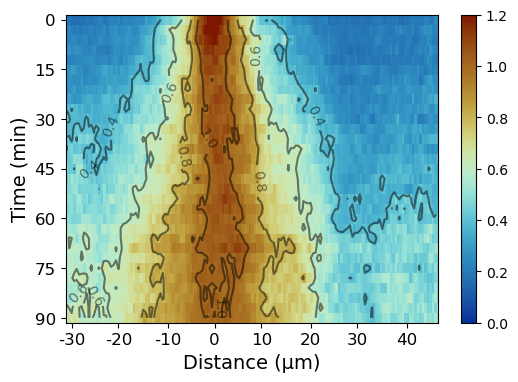

In [18]:
plt.figure(figsize=(6,4))
plt.imshow(df_N, cmap=cmap, vmin=0, vmax=1.2, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0,0.2,0.4,0.6,0.8,1.0,1.2])
contours = plt.contour(df_N, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks([2,21,41,60,79,99,118,138], [-30,-20,-10,0,10,20,30,40], rotation=0, fontsize=12)


plt.show()
#plt.savefig('_paper_figures/wt_N.png', dpi=300, bbox_inches='tight')

In [19]:
df_N.columns.values

array(['-30.9', '-30.385', '-29.87', '-29.355', '-28.84', '-28.325',
       '-27.81', '-27.295', '-26.78', '-26.265', '-25.75', '-25.235',
       '-24.72', '-24.205', '-23.69', '-23.175', '-22.66', '-22.145',
       '-21.63', '-21.115', '-20.6', '-20.085', '-19.57', '-19.055',
       '-18.54', '-18.025', '-17.51', '-16.995', '-16.48', '-15.965',
       '-15.45', '-14.935', '-14.42', '-13.905', '-13.39', '-12.875',
       '-12.36', '-11.845', '-11.33', '-10.815', '-10.3', '-9.785',
       '-9.27', '-8.755', '-8.24', '-7.725', '-7.21', '-6.695', '-6.18',
       '-5.665', '-5.15', '-4.635', '-4.12', '-3.605', '-3.09', '-2.575',
       '-2.06', '-1.545', '-1.03', '-0.515', '0.0', '0.515', '1.03',
       '1.545', '2.06', '2.575', '3.09', '3.605', '4.12', '4.635', '5.15',
       '5.665', '6.18', '6.695', '7.21', '7.725', '8.24', '8.755', '9.27',
       '9.785', '10.3', '10.815', '11.33', '11.845', '12.36', '12.875',
       '13.39', '13.905', '14.42', '14.935', '15.45', '15.965', '16.48',
   

In [20]:
np.where(df_N.columns.values == '40.17')

(array([138], dtype=int64),)

### WT peripheral figure

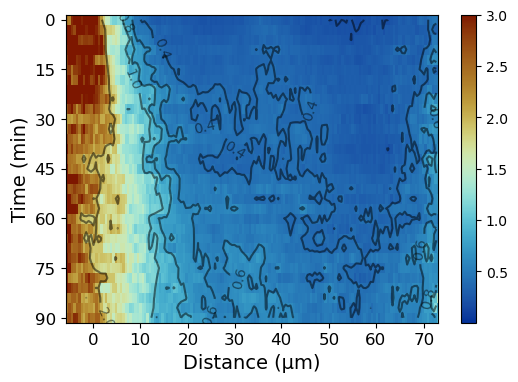

In [21]:
plt.figure(figsize=(6,4))
plt.imshow(df_P, cmap=cmap, vmin=0, vmax=3.0, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0.5,1.0,1.5,2.0,2.5,3.0])
contours = plt.contour(df_P, levels=[0.2, 0.4, 0.6, 0.8, 1.0, 2.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks([11,30,50,69,88,108,127,147], [0,10,20,30,40,50,60,70], rotation=0, fontsize=12)

plt.show()
#plt.savefig('_paper_figures/wt_P.png', dpi=300, bbox_inches='tight')

In [22]:
#normalize df_N and df_P by min and max value of the entire dataframe
df_N_norm = (df_N - df_N.min().min()) / (df_N.max().max() - df_N.min().min())
df_P_norm = (df_P - df_P.min().min()) / (df_P.max().max() - df_P.min().min())

### WT perinuclear figure (talk)

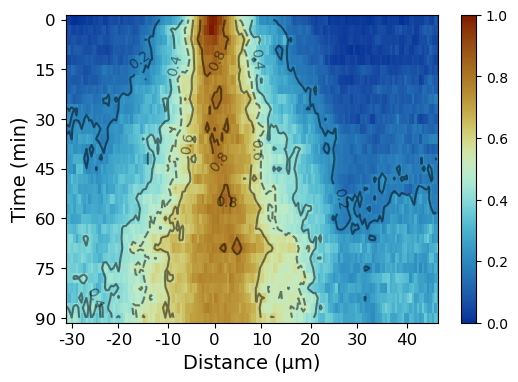

In [23]:
plt.figure(figsize=(6,4))
plt.imshow(df_N_norm, cmap=cmap, vmin=0.0, vmax=1.0, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0,0.2,0.4,0.6,0.8,1.0,1.2])
contours = plt.contour(df_N_norm, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.contour(df_N_norm, levels=[0.5], colors='black', alpha=0.5, linestyles='dashed')
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks([2,21,41,60,79,99,118,138], [-30,-20,-10,0,10,20,30,40], rotation=0, fontsize=12)

plt.show()
#plt.savefig('_paper_figures/wt_N_norm.png', dpi=300, bbox_inches='tight')

### WT peripheral figure (talk)

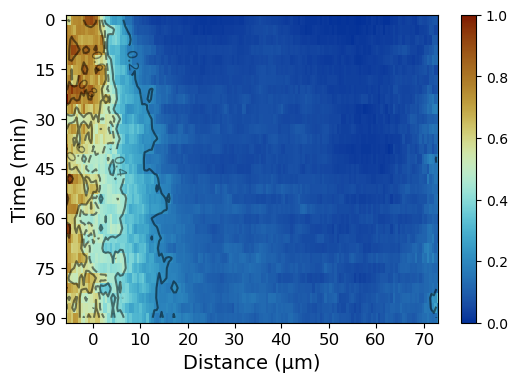

In [24]:
plt.figure(figsize=(6,4))
plt.imshow(df_P_norm, cmap=cmap, vmin=0, vmax=1, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0,0.2,0.4,0.6,0.8,1.0,1.2])
contours = plt.contour(df_P_norm, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.contour(df_P_norm, levels=[0.5], colors='black', alpha=0.5, linestyles='dashed')
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks([11,30,50,69,88,108,127,147], [0,10,20,30,40,50,60,70], rotation=0, fontsize=12)

plt.show()
#plt.savefig('_paper_figures/wt_P_norm.png', dpi=300, bbox_inches='tight')

### Plotting only the line profiles for a selection of timepoints and cropping on the center

In [25]:
timepoints = [0,15,30,45,60,75,90]

df_N_norm_selection = df_N_norm.loc[timepoints]
df_P_norm_selection = df_P_norm.loc[timepoints]

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

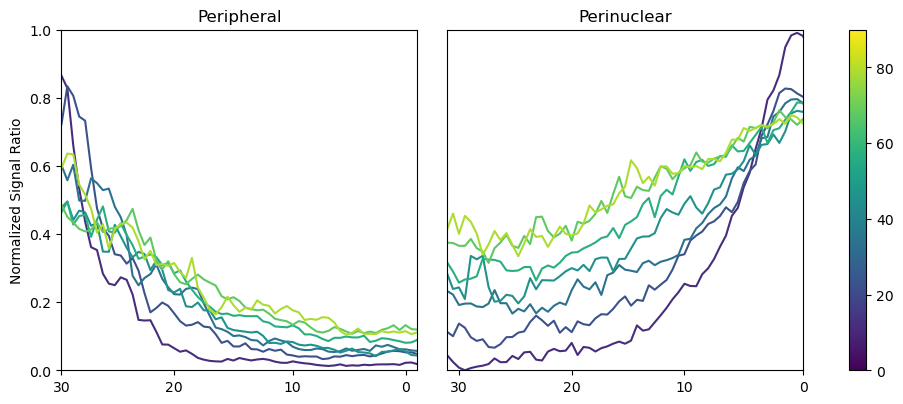

In [26]:
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=0, vmax=90))

fig, ax = plt.subplots(1,2, sharey=True, figsize=(10,4))
fig.tight_layout()
sns.lineplot(data=df_N_norm_selection.transpose(), dashes=False, palette='viridis', legend=False, ax=ax[1])
sns.lineplot(data=df_P_norm_selection.transpose(), dashes=False, palette='viridis', legend=False, ax=ax[0])
ax[1].figure.colorbar(sm, ticks=[0,20,40,60,80], ax=ax)
ax[1].set_xticks([2,21,40,60], [30,20,10,0])
ax[0].set_xticks([11,30,50,69], [30,20,10,0])
ax[1].tick_params(left=False)
ax[1].set_xlim(0, 60)
ax[0].set_xlim(11, 71)
ax[0].set_ylim(0, 1)
ax[0].set_ylabel('Normalized Signal Ratio')
ax[0].set_title('Peripheral')
ax[1].set_title('Perinuclear')
plt.ylim(0, 1)

plt.show()

### And plotting the corresponding cropped kymos

#### perinuclear

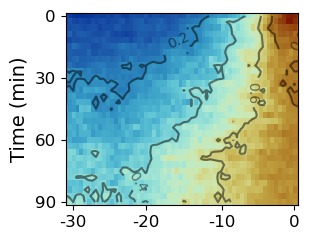

In [30]:
plt.figure(figsize=(3,2.5))
plt.imshow(df_N_norm, cmap=cmap, vmin=0.0, vmax=1.0, aspect='auto', interpolation='none')
contours = plt.contour(df_N_norm, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=12)
plt.xlim(0, 61)
plt.xticks([2,21,41,60], [-30,-20,-10,0], rotation=0, fontsize=12)

plt.show()
#plt.savefig('_paper_figures/WT_N_sim_comp.png', dpi=300, bbox_inches='tight')

#### peripheral

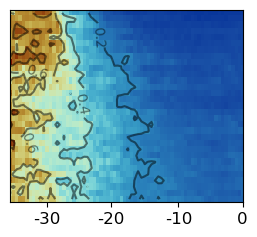

In [123]:
fig, ax = plt.subplots(figsize=(3,2.5))
im = ax.imshow(df_P_norm, cmap=cmap, vmin=0, vmax=1, aspect='auto', interpolation='none')
#fig.colorbar(im, ticks=[0,0.5,1.0])
contours = plt.contour(df_P_norm, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.tick_params(left=False, labelleft=False)
plt.xticks([11,30,50,69], [-30,-20,-10,0], rotation=0, fontsize=12)
plt.xlim(0, 69)

plt.show()
#plt.savefig('_paper_figures/WT_P_sim_comp.png', dpi=300, bbox_inches='tight')

# The example plot for a single movie

In [4]:
filename = '221020_S1_arches_post2_s3_N_lineProfile_tidy.csv'
folder = 'wt'

df_example = pd.read_csv(folder + '/all_tidy/' + filename)
df_example_red = rewrite_tidy_dataframe(df_example, 'red', -43.775, 53.045)
df_example_green = rewrite_tidy_dataframe(df_example, 'green', -43.775, 53.045)
df_example_ratio = rewrite_tidy_dataframe(df_example, 'ratio', -43.775, 53.045)

In [5]:
timepoints = [0,30,60,90]

df_example_red_selection = df_example_red.loc[timepoints]
df_example_green_selection = df_example_green.loc[timepoints]

#df_example_red_selection = bin_dataframe(df_example_red_selection,5)
#df_example_green_selection = bin_dataframe(df_example_green_selection,5)
df_example_ratio_selection = df_example_ratio.loc[timepoints]

### Example of a perinuclear photoconversion figure

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

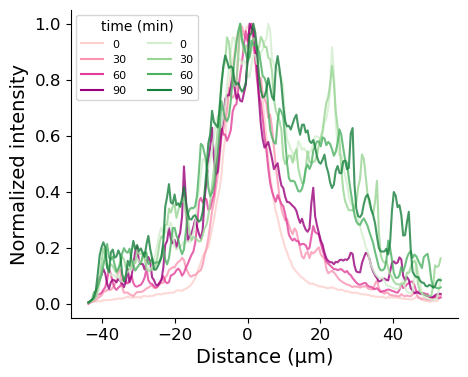

In [12]:
fig, ax = plt.subplots(figsize=(5,4))

sns.lineplot(df_example_red_selection.transpose(), palette='RdPu', dashes=False, alpha=0.8)
sns.lineplot(df_example_green_selection.transpose(), palette='Greens', dashes=False, alpha=0.8)

plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks(fontsize=12)
plt.ylabel('Normalized intensity', fontsize=14)
plt.yticks(fontsize=12)
plt.legend(ncols=2, fontsize=8, title='time (min)')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('_paper_figures/wt_example_lines.png', dpi=300, bbox_inches='tight')

In [8]:
#df_example_red = bin_dataframe(df_example_red, 5)
#df_example_green = bin_dataframe(df_example_green, 5)
#df_example_ratio = bin_dataframe(df_example_ratio, 5)

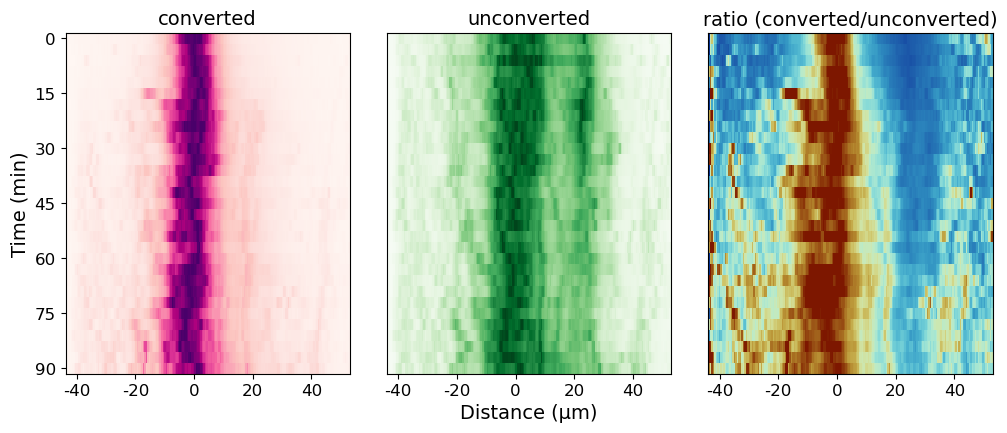

In [14]:
fig,ax = plt.subplots(1,3, sharey=True, figsize=(10,4))
fig.tight_layout()
ax[0].imshow(df_example_red, aspect='auto', vmin=0, vmax=1, cmap='RdPu', interpolation='none')
ax[1].imshow(df_example_green, aspect='auto', vmin=0, vmax=1, cmap='Greens', interpolation='none')
ax[2].imshow(df_example_ratio, aspect='auto', vmin=0, vmax=1, cmap=cmap, interpolation='none')

ax[0].set_ylabel('Time (min)', fontsize=14)
ax[0].set_yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
ax[1].set_xlabel('Distance (µm)', fontsize=14)
#ax[0].set_xticks([13,52,91,130,169], [-40,-20,0,20,40], rotation=0, fontsize=12)
#ax[1].set_xticks([13,52,91,130,169], [-40,-20,0,20,40], rotation=0, fontsize=12)
#ax[2].set_xticks([13,52,91,130,169], [-40,-20,0,20,40], rotation=0, fontsize=12)
ax[0].set_xticks([7,46,85,124,163], [-40,-20,0,20,40], rotation=0, fontsize=12)
ax[1].set_xticks([7,46,85,124,163], [-40,-20,0,20,40], rotation=0, fontsize=12)
ax[2].set_xticks([7,46,85,124,163], [-40,-20,0,20,40], rotation=0, fontsize=12)
ax[1].tick_params(left=False)
ax[2].tick_params(left=False)
ax[0].set_title('converted', fontsize=14)
ax[1].set_title('unconverted', fontsize=14)
ax[2].set_title('ratio (converted/unconverted)', fontsize=14)

plt.show()
#plt.savefig('_paper_figures/all_channels_example.png', dpi=300, bbox_inches='tight')

# Combined kymographs for TRAK1 and TRAK2

In [131]:
df_N, df_P = open_kymographs('wt', 'ratio', ratio_calculation='median')
df_N_ctrl, df_P_ctrl = open_kymographs('si_control', 'ratio', ratio_calculation='median')
df_N_TRAK1_kd, df_P_TRAK1_kd = open_kymographs('TRAK1_kd', 'ratio', ratio_calculation='median')
df_N_TRAK2_kd, df_P_TRAK2_kd = open_kymographs('TRAK2_kd', 'ratio', ratio_calculation='median')
df_N_TRAK1_oe, df_P_TRAK1_oe = open_kymographs('TRAK1_oe', 'ratio', ratio_calculation='median')
df_N_TRAK2_oe, df_P_TRAK2_oe = open_kymographs('TRAK2_oe', 'ratio', ratio_calculation='median')

df_N = df_N / df_N.max().max()
df_N_ctrl = df_N_ctrl / df_N_ctrl.max().max()
df_N_TRAK1_kd = df_N_TRAK1_kd / df_N_TRAK1_kd.max().max()
df_N_TRAK2_kd = df_N_TRAK2_kd / df_N_TRAK2_kd.max().max()
df_N_TRAK1_oe = df_N_TRAK1_oe / df_N_TRAK1_oe.max().max()
df_N_TRAK2_oe = df_N_TRAK2_oe / df_N_TRAK2_oe.max().max()


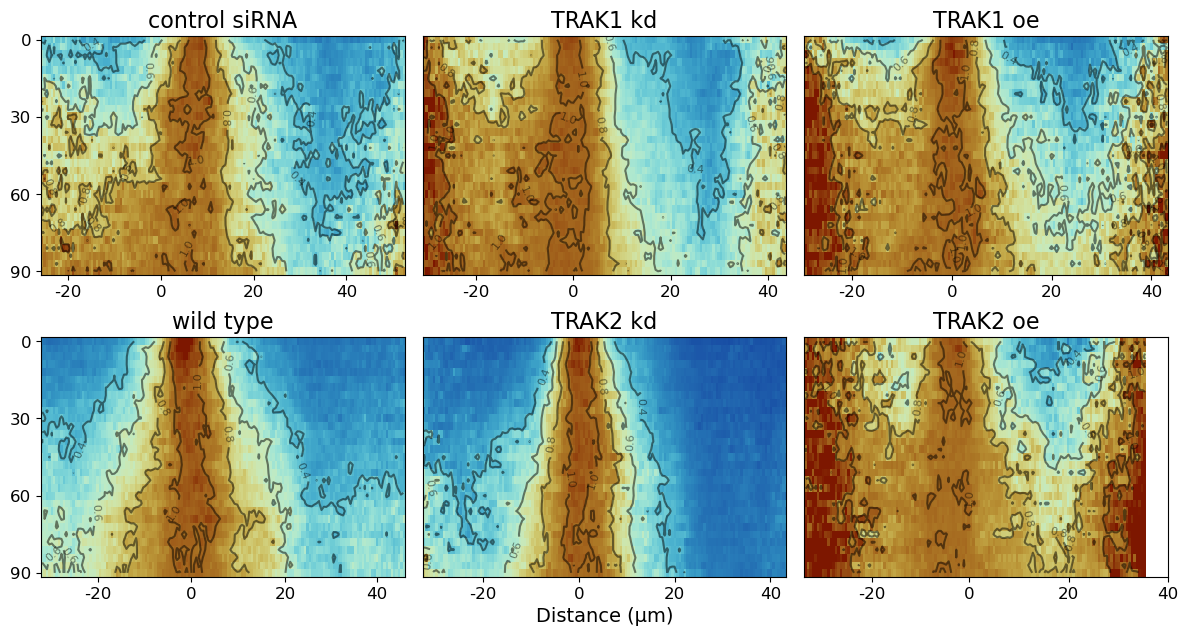

In [132]:
fontsize_contour = 8
fontsize_ticks = 12
fontsize_tick_labels = 14
fontsize_title = 16

fig, ax = plt.subplots(2,3, sharey=True, figsize=(12,6))
fig.tight_layout()
plt.subplots_adjust(hspace=0.26, wspace=0.05)

ax[0,0].imshow(df_N_ctrl, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[0,0].contour(df_N_ctrl, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0,0].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[0,0].set_xticks([11,50,89,128], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[0,0].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[0,0].set_title('control siRNA', fontsize=fontsize_title)

ax[1,0].imshow(df_N, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[1,0].contour(df_N, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1,0].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[1,0].set_xticks([23,62,101,139], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[1,0].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[1,0].set_title('wild type', fontsize=fontsize_title)

ax[0,1].imshow(df_N_TRAK1_kd, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[0,1].contour(df_N_TRAK1_kd, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0,1].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[0,1].set_xticks([21,60,99,138], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[0,1].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[0,1].tick_params(left=False)
ax[0,1].set_title('TRAK1 kd', fontsize=fontsize_title)

ax[0,2].imshow(df_N_TRAK1_oe, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[0,2].contour(df_N_TRAK1_oe, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0,2].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[0,2].set_xticks([18,57,96,135], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[0,2].tick_params(left=False)
ax[0,2].set_title('TRAK1 oe', fontsize=fontsize_title)

ax[1,1].imshow(df_N_TRAK2_kd, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[1,1].contour(df_N_TRAK2_kd, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1,1].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[1,1].set_xticks([24,63,102,141], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[1,1].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[1,1].set_xlabel('Distance (µm)', fontsize=fontsize_tick_labels)
ax[1,1].tick_params(left=False)
ax[1,1].set_title('TRAK2 kd', fontsize=fontsize_title)

ax[1,2].imshow(df_N_TRAK2_oe, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[1,2].contour(df_N_TRAK2_oe, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1,2].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[1,2].set_xticks([26,64,103,142], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[1,2].tick_params(left=False)
ax[1,2].set_title('TRAK2 oe', fontsize=fontsize_title)

plt.show()
#plt.savefig('_paper_figures/TRAK_kymos_ho.png', dpi=300, bbox_inches='tight')


In [133]:
#custom cmap to gray out the periphery
#custom_cmap = cm.roma_r(np.arange(256))
#custom_cmap[255:, :] = np.array([0.8, 0.8, 0.8, 1])
#cmap = mpl.colors.ListedColormap(custom_cmap, name='roma_r_gray', N=custom_cmap.shape[0])

#### Truncate the kymographs at +- 20um

In [134]:
df_N_TRAK1_kd = df_N_TRAK1_kd.loc[:, '-20.085':'20.085']
df_N_TRAK1_oe = df_N_TRAK1_oe.loc[:, '-20.085':'20.085']
df_N_TRAK2_oe = df_N_TRAK2_oe.loc[:, '-20.085':'20.085']

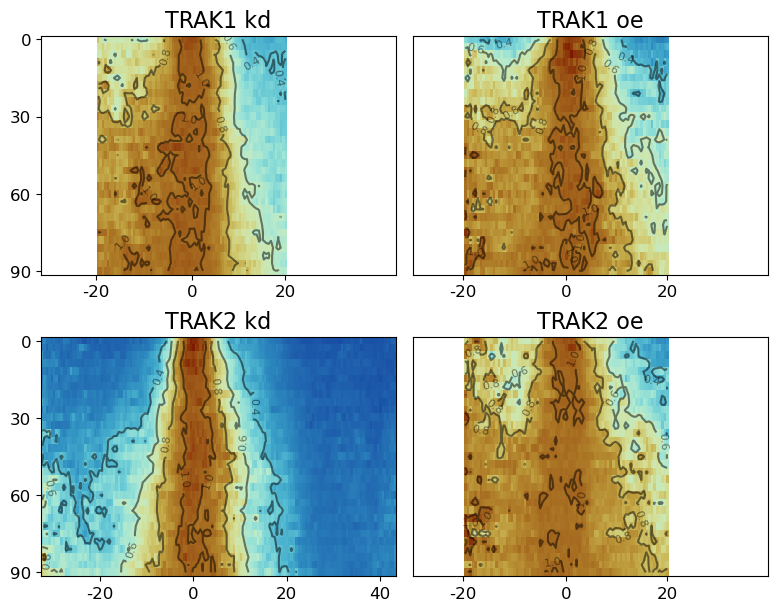

In [137]:
fig, ax = plt.subplots(2,2, sharey=True, figsize=(8,6))
fig.tight_layout()
plt.subplots_adjust(hspace=0.26, wspace=0.05)

ax[0,0].imshow(df_N_TRAK1_kd, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[0,0].contour(df_N_TRAK1_kd, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0,0].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[0,0].set_xlim(-24,124)
ax[0,0].set_xticks([-1,39,78], [-20,0,20], rotation=0, fontsize=fontsize_ticks)
ax[0,0].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[0,0].set_title('TRAK1 kd', fontsize=fontsize_title)

ax[0,1].imshow(df_N_TRAK1_oe, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[0,1].contour(df_N_TRAK1_oe, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0,1].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[0,1].set_xlim(-20,117)
ax[0,1].set_xticks([-1,39,78], [-20,0,20], rotation=0, fontsize=fontsize_ticks)
ax[0,1].tick_params(left=False)
ax[0,1].set_title('TRAK1 oe', fontsize=fontsize_title)

ax[1,0].imshow(df_N_TRAK2_kd, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[1,0].contour(df_N_TRAK2_kd, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1,0].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[1,0].set_xticks([24,63,102,141], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[1,0].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[1,0].set_title('TRAK2 kd', fontsize=fontsize_title)

ax[1,1].imshow(df_N_TRAK2_oe, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[1,1].contour(df_N_TRAK2_oe, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1,1].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[1,1].set_xlim(-20,117)
ax[1,1].set_xticks([-1,39,78], [-20,0,20], rotation=0, fontsize=fontsize_ticks)
ax[1,1].tick_params(left=False)
ax[1,1].set_title('TRAK2 oe', fontsize=fontsize_title)

plt.show()
#plt.savefig('_paper_figures/TRAK_kymos_ho.png', dpi=300, bbox_inches='tight')

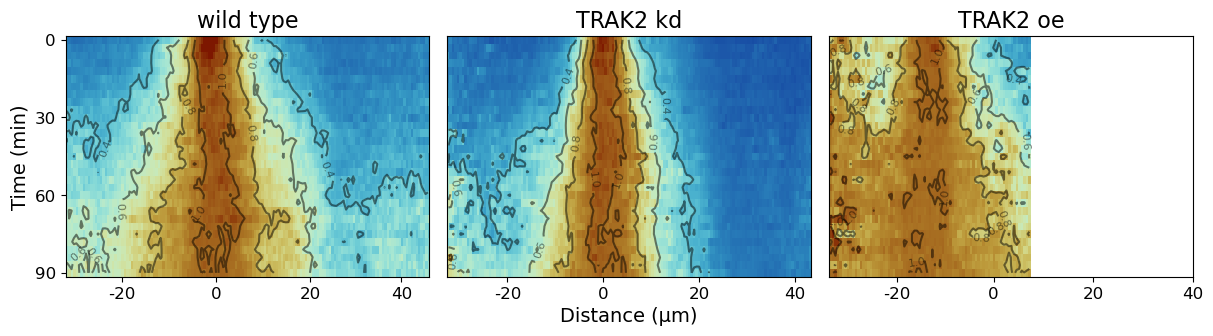

In [138]:
fontsize_contour = 8
fontsize_ticks = 12
fontsize_tick_labels = 14
fontsize_title = 16

fig, ax = plt.subplots(1,3, sharey=True, figsize=(12,3))
fig.tight_layout()
plt.subplots_adjust(hspace=0.26, wspace=0.05)

ax[0].imshow(df_N, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[0].contour(df_N, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[0].set_xticks([23,62,101,139], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[0].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[0].set_ylabel('Time (min)', fontsize=fontsize_tick_labels)
ax[0].set_title('wild type', fontsize=fontsize_title)

ax[1].imshow(df_N_TRAK2_kd, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[1].contour(df_N_TRAK2_kd, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[1].set_xticks([24,63,102,141], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[1].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[1].tick_params(left=False)
ax[1].set_xlabel('Distance (µm)', fontsize=fontsize_tick_labels)
ax[1].set_title('TRAK2 kd', fontsize=fontsize_title)

ax[2].imshow(df_N_TRAK2_oe, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[2].contour(df_N_TRAK2_oe, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[2].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[2].set_xticks([26,64,103,142], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[2].tick_params(left=False)
ax[2].set_title('TRAK2 oe', fontsize=fontsize_title)

plt.show()
#plt.savefig('_paper_figures/TRAK2_kymos_talk.png', dpi=300, bbox_inches='tight')

# Combined kymographs with galactose

In [6]:
cmap = cm.roma_r

df_N_gal_on, df_P_gal_on = open_kymographs('galactose', 'ratio', ratio_calculation='median')
df_N_gal_48h, df_P_gal_48h = open_kymographs('galactose_48h', 'ratio', ratio_calculation='median')

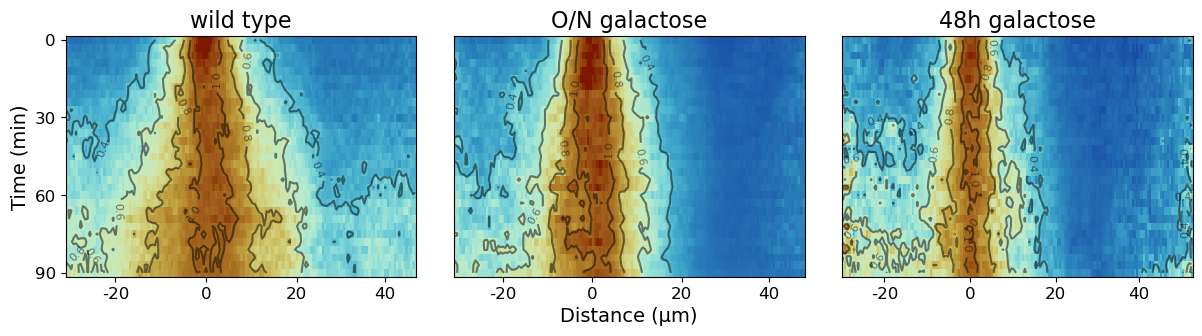

In [7]:
fontsize_contour = 8
fontsize_ticks = 12
fontsize_tick_labels = 14
fontsize_title = 16

fig, ax = plt.subplots(1,3, sharey=True, figsize=(12,3))
fig.tight_layout()
#plt.subplots_adjust(hspace=0.26, wspace=0.05)

ax[0].imshow(df_N, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[0].contour(df_N, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[0].set_xticks([21,60,99,137], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[0].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[0].set_ylabel('Time (min)', fontsize=fontsize_tick_labels)
ax[0].set_title('wild type', fontsize=fontsize_title)

ax[1].imshow(df_N_gal_on, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[1].contour(df_N_gal_on, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[1].set_xticks([21,60,99,137], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[1].set_xlabel('Distance (µm)', fontsize=fontsize_tick_labels)
ax[1].tick_params(left=False)
ax[1].set_title('O/N galactose', fontsize=fontsize_title)

ax[2].imshow(df_N_gal_48h, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[2].contour(df_N_gal_48h, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[2].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[2].set_xticks([19,58,97,135], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[2].tick_params(left=False)
ax[2].set_title('48h galactose', fontsize=fontsize_title)

plt.show()
#plt.savefig('_paper_figures/galactose_kymos.png', dpi=300, bbox_inches='tight')

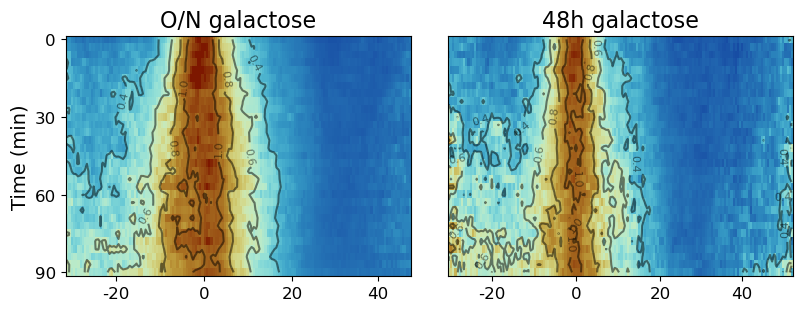

In [10]:
fig, ax = plt.subplots(1,2, sharey=True, figsize=(8,3))
fig.tight_layout()
#plt.subplots_adjust(hspace=0.26, wspace=0.05)

ax[0].imshow(df_N_gal_on, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
contours = ax[0].contour(df_N_gal_on, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[0].set_xticks([22,61,100,138], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[0].set_ylabel('Time (min)', fontsize=fontsize_tick_labels)
ax[0].set_yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=fontsize_ticks)
ax[0].set_title('O/N galactose', fontsize=fontsize_title)

im = ax[1].imshow(df_N_gal_48h, aspect='auto', vmin=0, vmax=1.2, cmap=cmap, interpolation='none')
#fig.colorbar(im, ticks=[0,0.2,0.4,0.6,0.8,1.0,1.2])
contours = ax[1].contour(df_N_gal_48h, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1].clabel(contours, inline=True, fontsize=fontsize_contour)
ax[1].set_xticks([20,59,98,136], [-20,0,20,40], rotation=0, fontsize=fontsize_ticks)
ax[1].tick_params(left=False)
ax[1].set_title('48h galactose', fontsize=fontsize_title)

plt.show()
#plt.savefig('_paper_figures/galactose_kymos.png', dpi=300, bbox_inches='tight')